# Exploratory Data Analysis (EDA)

**Project:** Clean Sales Dataset  
**Input:** `data/clean_sales.csv` from Phase 3.2

## Goal
Explore the cleaned sales data, answer business questions with evidence, identify limitations, and recommend reasonable next steps.

> **Important:** This dataset is suitable for practicing EDA. Unless it contains verified revenue, cost, profit, customer, and date fields, do not use it to make claims about profitability, customer lifetime value, or sales trends over time.

## 1. Business questions

We will investigate these questions:

1. Which product categories have the highest order-row counts and total quantity?
2. Which cities have the highest total quantity?
3. How are quantities and product weights distributed, and are there potential outliers?
4. Is there a relationship between order quantity and weight?
5. How many records still need data-quality review, and which fields need attention?

**How to interpret results:** These questions describe the dataset. They do not automatically explain *why* a category or city performs differently.

## 2. Load the clean dataset

Install dependencies if needed in a terminal:

```bash
pip install pandas numpy matplotlib seaborn
```

The code looks for `data/clean_sales.csv` relative to this notebook's folder. If your file is elsewhere, update `DATA_PATH`.


In [21]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
DATA_PATH = DATA_DIR / "clean_sales.csv"
CHART_DIR = DATA_DIR / "eda_charts"
DATA_DIR.mkdir(parents=True, exist_ok=True)
CHART_DIR.mkdir(parents=True, exist_ok=True)

# If clean_sales.csv is missing, create a small practice dataset.
# Replace this sample later with your real cleaned dataset from Phase 3.2.
if not DATA_PATH.exists():
    sample_data = {
        "Order_ID": [1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009, 1010,
                     1011, 1012, 1013, 1014, 1015, 1016, 1017, 1018, 1019, 1020],
        "City": ["Lahore", "Karachi", "Lahore", "Islamabad", "Karachi",
                 "Lahore", "Peshawar", "Karachi", "Islamabad", "Lahore",
                 "Multan", "Karachi", "Lahore", "Faisalabad", "Islamabad",
                 "Lahore", "Karachi", "Peshawar", "Multan", "Faisalabad"],
        "Category": ["Electronics", "Clothing", "Grocery", "Furniture", "Electronics",
                     "Clothing", "Grocery", "Home & Kitchen", "Electronics", "Grocery",
                     "Clothing", "Furniture", "Electronics", "Grocery", "Home & Kitchen",
                     "Clothing", "Electronics", "Furniture", "Grocery", "Clothing"],
        "Order_Status": ["Completed", "Shipped", "Completed", "Pending", "Cancelled",
                         "Completed", "Shipped", "Completed", "Returned", "Completed",
                         "Pending", "Completed", "Shipped", "Completed", "Cancelled",
                         "Completed", "Pending", "Shipped", "Completed", "Completed"],
        "Quantity": [2, 3, 10, 1, 2, 4, 8, 2, 1, 12, 3, 1, 2, 9, 2, 5, 1, 1, 7, 4],
        "Weight_kg": [1.2, 0.4, 5.0, 8.5, 2.0, 0.5, 4.0, 3.2, 1.8, 6.0,
                      0.7, 9.0, 1.5, 4.5, 2.5, 0.6, 2.1, 7.5, 3.8, 0.8],
        "Needs_Review": [False, False, False, False, False, False, False, False, True, False,
                         False, False, False, False, True, False, False, False, False, False],
    }
    pd.DataFrame(sample_data).to_csv(DATA_PATH, index=False)
    print(f"Created a sample practice dataset: {DATA_PATH}")
    print("This is sample data for practicing EDA, not your original business data.")

df = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH}")
print(f"Rows: {len(df):,} | Columns: {df.shape[1]:,}")
display(df.head())


Loaded: e:\RoadMap Practice\Phase 3\3.3 Exploratory Analysis\data\clean_sales.csv
Rows: 20 | Columns: 7


,Order_ID,City,Category,Order_Status,Quantity,Weight_kg,Needs_Review
0,1001,Lahore,Electronics,Completed,2,1.2,False
1,1002,Karachi,Clothing,Shipped,3,0.4,False
2,1003,Lahore,Grocery,Completed,10,5.0,False
3,1004,Islamabad,Furniture,Pending,1,8.5,False
4,1005,Karachi,Electronics,Cancelled,2,2.0,False


## 3. Initial exploration and data quality

Check the dataset's size, column types, summary statistics, missing values, duplicates, and available categories. These checks help us decide which analyses are safe to perform.

In [22]:
print("Dataset shape:", df.shape)

print("\nColumn data types:")
display(df.dtypes.rename("dtype").to_frame())

print("\nSummary statistics (numeric columns):")
display(df.describe(include="number").T)

print("\nSummary statistics (all columns):")
display(df.describe(include="all").T)

quality = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True),
})
display(quality.sort_values("missing_count", ascending=False))

print("Exact duplicate rows:", int(df.duplicated().sum()))


Dataset shape: (20, 7)

Column data types:


,dtype
Order_ID,int64
City,str
Category,str
Order_Status,str
Quantity,int64
Weight_kg,float64
Needs_Review,bool



Summary statistics (numeric columns):


,count,mean,std,min,25%,50%,75%,max
Order_ID,20.0,1010.50,5.916080,1001.0,1005.75,1010.5,1015.250,1020.0
Quantity,20.0,4.00,3.387283,1.0,1.75,2.5,5.500,12.0
Weight_kg,20.0,3.28,2.712078,0.4,1.10,2.3,4.625,9.0



Summary statistics (all columns):


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order_ID,20.0,NaN,NaN,NaN,1010.5,5.91608,1001.0,1005.75,1010.5,1015.25,1020.0
City,20,6,Lahore,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,20,5,Electronics,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_Status,20,5,Completed,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,20.0,NaN,NaN,NaN,4.0,3.387283,1.0,1.75,2.5,5.5,12.0
Weight_kg,20.0,NaN,NaN,NaN,3.28,2.712078,0.4,1.1,2.3,4.625,9.0
Needs_Review,20,2,False,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing_count,missing_percent,unique_values
Order_ID,0,0.0,20
City,0,0.0,6
Category,0,0.0,5
Order_Status,0,0.0,5
Quantity,0,0.0,10
Weight_kg,0,0.0,20
Needs_Review,0,0.0,2


Exact duplicate rows: 0


In [23]:
# Review distinct values for common categorical columns, when present.
for column in ["City", "Category", "Order_Status"]:
    if column in df.columns:
        print(f"\nDistinct values in {column}:")
        print(sorted(df[column].dropna().astype(str).unique().tolist()))


Distinct values in City:
['Faisalabad', 'Islamabad', 'Karachi', 'Lahore', 'Multan', 'Peshawar']

Distinct values in Category:
['Clothing', 'Electronics', 'Furniture', 'Grocery', 'Home & Kitchen']

Distinct values in Order_Status:
['Cancelled', 'Completed', 'Pending', 'Returned', 'Shipped']


### Data-quality interpretation

After running the cells above, write down:
- Which columns have missing values?
- Are there duplicate rows, and should they really be duplicates?
- Do category, city, and status values look consistent?
- Are numeric-looking columns stored as numbers or text?

Do not delete missing values or duplicates automatically. First determine what they mean in the business context.


## 4. Prepare numeric columns

Convert `Quantity` and `Weight_kg` to numeric values only if those columns exist. Invalid text will become missing (`NaN`), so we record how many values could not be converted.


In [24]:
numeric_columns = [c for c in ["Quantity", "Weight_kg"] if c in df.columns]
conversion_report = []

for column in numeric_columns:
    before = df[column].notna().sum()
    converted = pd.to_numeric(df[column], errors="coerce")
    newly_missing = int((df[column].notna() & converted.isna()).sum())
    df[column] = converted
    conversion_report.append({
        "column": column,
        "non_missing_before": int(before),
        "newly_missing_after_conversion": newly_missing,
    })

display(pd.DataFrame(conversion_report))
display(df[numeric_columns].describe().T if numeric_columns else pd.DataFrame(
    {"Note": ["No Quantity or Weight_kg column found. Update the column names if your dataset uses different names."]}
))

,column,non_missing_before,newly_missing_after_conversion
0,Quantity,20,0
1,Weight_kg,20,0


,count,mean,std,min,25%,50%,75%,max
Quantity,20.0,4.00,3.387283,1.0,1.75,2.5,5.500,12.0
Weight_kg,20.0,3.28,2.712078,0.4,1.10,2.3,4.625,9.0


## 5. Distribution analysis

Histograms help show the shape and spread of numeric values. Box plots can highlight unusually high or low values, but a flagged point is not automatically an error.

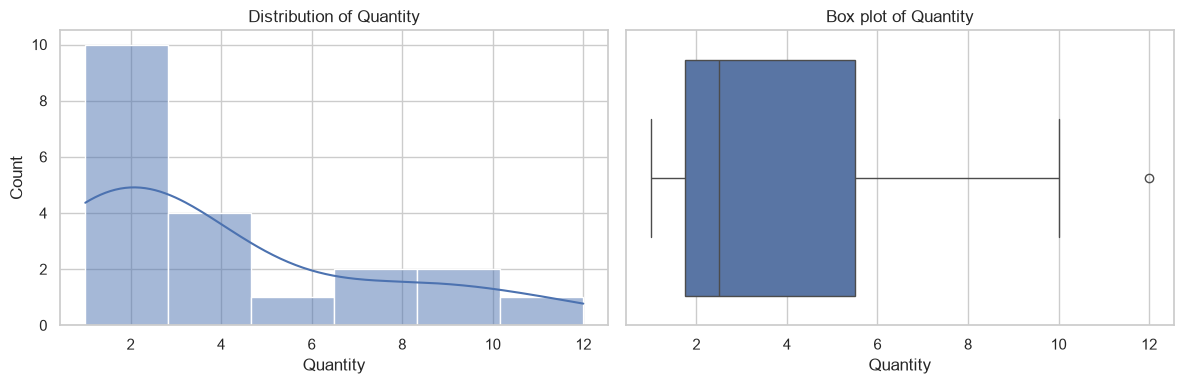

Numerical summary for Quantity:


,count,mean,std,min,25%,50%,75%,max
value,20.0,4.0,3.387283,1.0,1.75,2.5,5.5,12.0


Median: 2.50; IQR: 3.75


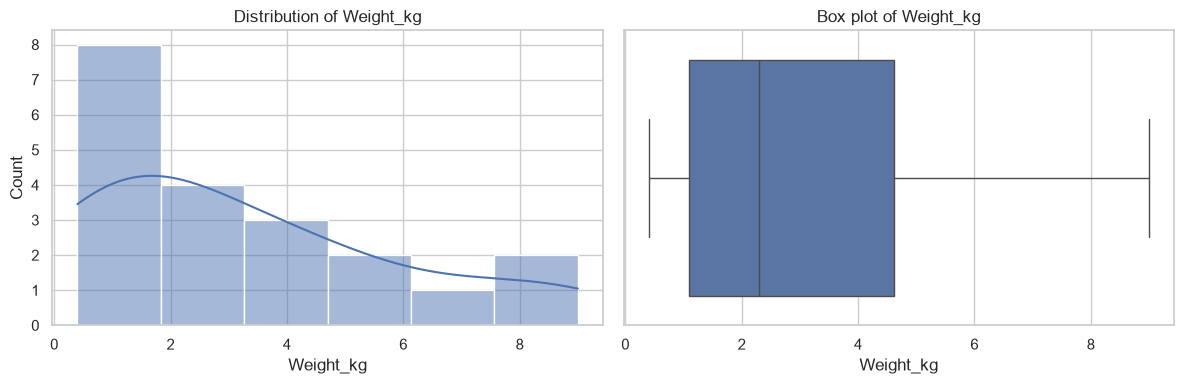

Numerical summary for Weight_kg:


,count,mean,std,min,25%,50%,75%,max
value,20.0,3.28,2.712078,0.4,1.1,2.3,4.625,9.0


Median: 2.30; IQR: 3.52


In [25]:
for column in numeric_columns:
    values = df[column].dropna()
    if values.empty:
        print(f"Skipping {column}: no numeric values.")
        continue

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(values, kde=True, ax=axes[0])
    axes[0].set_title(f"Distribution of {column}")
    axes[0].set_xlabel(column)

    sns.boxplot(x=values, ax=axes[1])
    axes[1].set_title(f"Box plot of {column}")
    axes[1].set_xlabel(column)

    plt.tight_layout()
    fig.savefig(CHART_DIR / f"{column.lower()}_distribution.png", dpi=150, bbox_inches="tight")
    plt.show()

    print(f"Numerical summary for {column}:")
    display(values.describe().to_frame("value").T)
    print(f"Median: {values.median():.2f}; IQR: {(values.quantile(0.75) - values.quantile(0.25)):.2f}")


### Distribution insights — write after viewing the plots

Use this template and replace the brackets with actual results:

- **Quantity:** Most values are concentrated around **[range]**. The median is **[value]**, compared with a mean of **[value]**.
- **Weight:** Values range from **[minimum]** to **[maximum]** kg. The box plot shows **[no / some]** potential outliers.
- **Limit:** Outliers require investigation against the original order or product records before correction or removal.


## 6. Segment analysis

Compare category, city, and order-status groups. `Order_Rows` counts rows with a non-missing `Order_ID`; it is not necessarily a count of unique orders. If one order can have multiple product rows, use `nunique` for unique order counts.


,Order_Rows,Unique_Orders,Total_Quantity,Average_Quantity,Average_Weight_kg
Category,,,,,
Clothing,5,5,19,3.8,0.600000
Electronics,5,5,8,1.6,1.720000
Furniture,3,3,3,1.0,8.333333
Grocery,5,5,46,9.2,4.660000
Home & Kitchen,2,2,4,2.0,2.850000


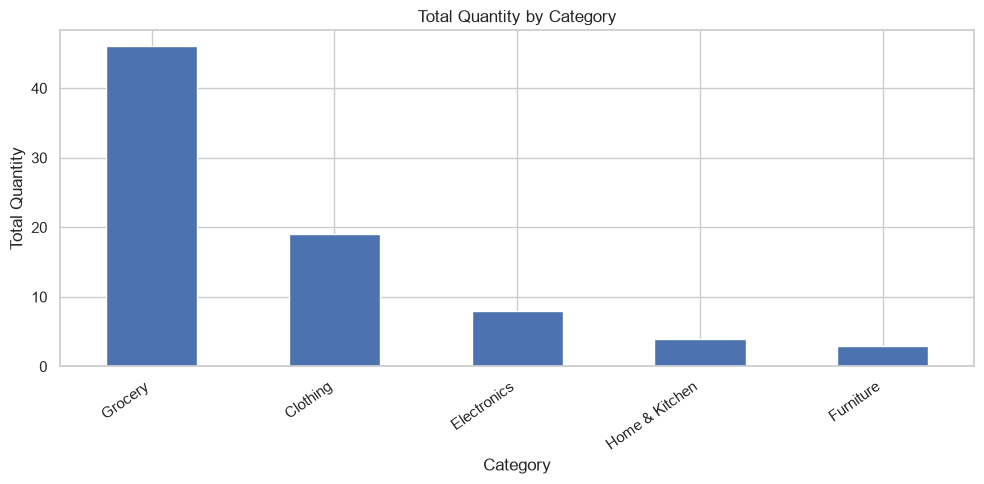

In [26]:
# Category comparison
if "Category" in df.columns:
    aggregations = {}
    if "Order_ID" in df.columns:
        aggregations["Order_Rows"] = ("Order_ID", "count")
        aggregations["Unique_Orders"] = ("Order_ID", "nunique")
    if "Quantity" in df.columns:
        aggregations["Total_Quantity"] = ("Quantity", "sum")
        aggregations["Average_Quantity"] = ("Quantity", "mean")
    if "Weight_kg" in df.columns:
        aggregations["Average_Weight_kg"] = ("Weight_kg", "mean")

    if aggregations:
        category_summary = df.groupby("Category", dropna=False).agg(**aggregations).sort_index()
        display(category_summary)
        category_summary.to_csv(DATA_DIR / "eda_category_analysis.csv")

        metric = "Total_Quantity" if "Total_Quantity" in category_summary.columns else category_summary.columns[0]
        category_summary[metric].sort_values(ascending=False).plot(kind="bar", figsize=(10, 5))
        plt.title(f"{metric.replace('_', ' ')} by Category")
        plt.ylabel(metric.replace("_", " "))
        plt.xlabel("Category")
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        plt.savefig(CHART_DIR / "category_comparison.png", dpi=150, bbox_inches="tight")
        plt.show()
    else:
        print("No suitable columns available for category aggregation.")
else:
    print("No Category column found.")


,Order_Rows,Unique_Orders,Total_Quantity,Average_Quantity
City,,,,
Faisalabad,2,2,13,6.500000
Islamabad,3,3,4,1.333333
Karachi,5,5,9,1.800000
Lahore,6,6,35,5.833333
Multan,2,2,10,5.000000
Peshawar,2,2,9,4.500000


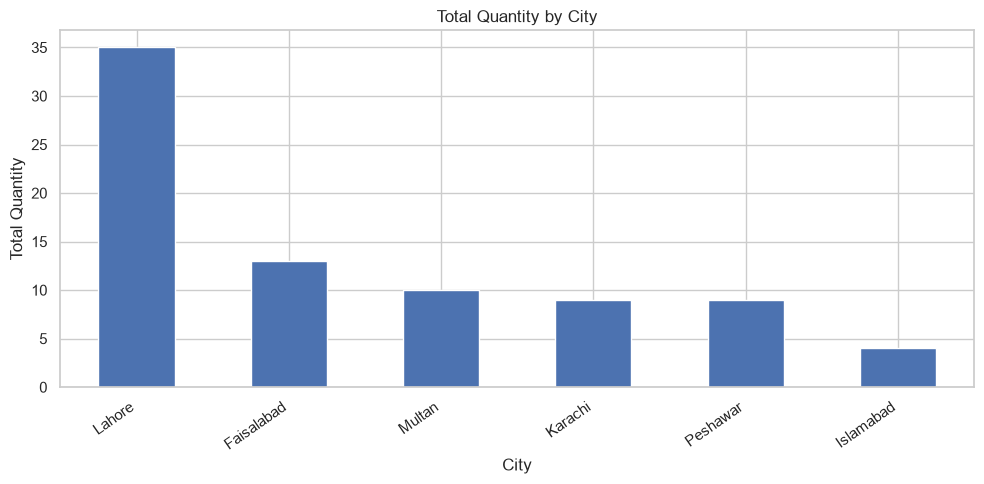

In [27]:
# City comparison
if "City" in df.columns:
    aggregations = {}
    if "Order_ID" in df.columns:
        aggregations["Order_Rows"] = ("Order_ID", "count")
        aggregations["Unique_Orders"] = ("Order_ID", "nunique")
    if "Quantity" in df.columns:
        aggregations["Total_Quantity"] = ("Quantity", "sum")
        aggregations["Average_Quantity"] = ("Quantity", "mean")

    if aggregations:
        city_summary = df.groupby("City", dropna=False).agg(**aggregations).sort_index()
        display(city_summary)
        city_summary.to_csv(DATA_DIR / "eda_city_analysis.csv")

        metric = "Total_Quantity" if "Total_Quantity" in city_summary.columns else city_summary.columns[0]
        city_summary[metric].sort_values(ascending=False).plot(kind="bar", figsize=(10, 5))
        plt.title(f"{metric.replace('_', ' ')} by City")
        plt.ylabel(metric.replace("_", " "))
        plt.xlabel("City")
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        plt.savefig(CHART_DIR / "city_comparison.png", dpi=150, bbox_inches="tight")
        plt.show()
    else:
        print("No suitable columns available for city aggregation.")
else:
    print("No City column found.")

,row_count
Order_Status,
Completed,10
Shipped,4
Pending,3
Cancelled,2
Returned,1


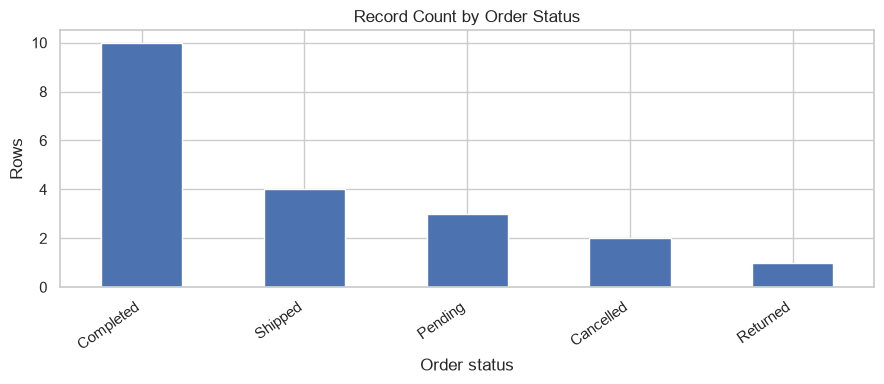

In [28]:
# Order status distribution
if "Order_Status" in df.columns:
    status_counts = df["Order_Status"].fillna("Missing").value_counts(dropna=False)
    display(status_counts.rename("row_count").to_frame())
    status_counts.to_csv(DATA_DIR / "eda_status_analysis.csv", header=["row_count"])

    status_counts.plot(kind="bar", figsize=(9, 4))
    plt.title("Record Count by Order Status")
    plt.ylabel("Rows")
    plt.xlabel("Order status")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.savefig(CHART_DIR / "order_status_counts.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("No Order_Status column found.")

### **Segment insights — write after checking the tables**

- **Category:** **[category]** has the highest **[total quantity / row count]**, at **[value]**.
- **City:** **[city]** has the highest **[total quantity / row count]**, at **[value]**.
- **Order status:** The most common status is **[status]**, with **[count]** rows.
- **Limit:** Counts and quantities alone do not establish revenue, profitability, demand growth, or performance per customer. Comparisons may also be unreliable if the sample is small or incomplete.

## 7. Relationship analysis

Check the relationship between quantity and weight if both columns exist. Correlation describes the strength and direction of a linear relationship; it does not prove that one variable causes the other.


Pearson correlation between Quantity and Weight_kg: 0.114


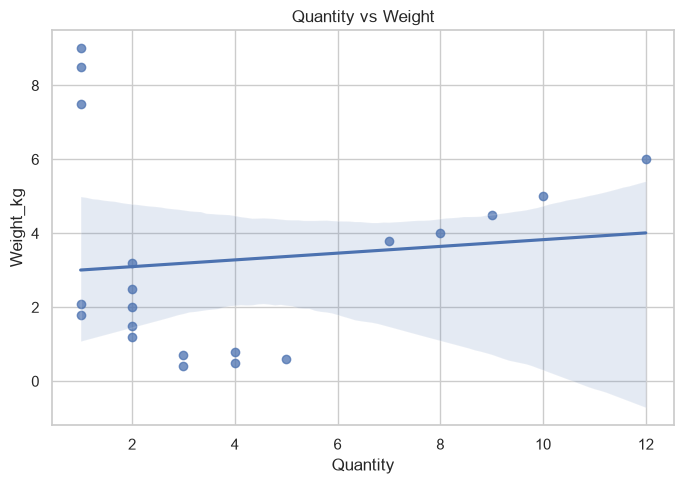

In [29]:
if {"Quantity", "Weight_kg"}.issubset(df.columns):
    pair = df[["Quantity", "Weight_kg"]].dropna()

    if len(pair) >= 2 and pair.nunique().min() > 1:
        correlation = pair["Quantity"].corr(pair["Weight_kg"], method="pearson")
        print(f"Pearson correlation between Quantity and Weight_kg: {correlation:.3f}")

        plt.figure(figsize=(7, 5))
        sns.regplot(data=pair, x="Quantity", y="Weight_kg", scatter_kws={"alpha": 0.75})
        plt.title("Quantity vs Weight")
        plt.tight_layout()
        plt.savefig(CHART_DIR / "quantity_vs_weight.png", dpi=150, bbox_inches="tight")
        plt.show()
    else:
        print("Not enough valid variation to calculate a meaningful correlation.")
else:
    print("Quantity and/or Weight_kg column missing; relationship analysis skipped.")

### Relationship insights — write after viewing the scatter plot

- Pearson correlation is **[value]**, suggesting a **[positive / negative / weak]** linear association in this dataset.
- The scatter plot shows **[describe the visible pattern and any unusual points]**.
- **Limitations:** A small dataset can produce unstable correlations. Weight may refer to one product, one item, or an entire order; confirm its definition. Correlation is not evidence of causation.


## 8. Key findings and limitations

Use the evidence from the cells above to complete these points. Do not leave placeholders in the final submitted notebook.

1. **Finding:** [State one result.]  
   **Evidence:** [Give the exact table value, count, percentage, or statistic.]
2. **Finding:** [State a second result.]  
   **Evidence:** [Give the exact value and relevant comparison.]
3. **Finding:** [State a data-quality or relationship result.]  
   **Evidence:** [Give the measured value.]

### Limitations to consider
- How many rows are present, and are they representative of the business?
- Are dates, prices, costs, customer identifiers, and returns available?
- Are quantities and weights defined consistently?
- Are missing or flagged categories still unresolved?
- Are row counts being confused with unique orders?


## 9. Business recommendations and further investigation

Make recommendations only when the findings support them. Use this checklist to develop the final recommendations:

- **Data quality:** Investigate unresolved review flags and confirm category, city, status, and weight values with the source records.
- **Inventory planning:** If a category has a high total quantity, validate the pattern over a longer period before changing stock levels.
- **Regional planning:** If a city has high order volume, compare it with population served, delivery capacity, costs, and time period before allocating more resources.
- **Order operations:** Review cancelled, returned, or pending orders with order dates and reasons before suggesting process changes.
- **Profitability:** Obtain selling price, discounts, cost of goods, shipping cost, and return cost before deciding which products are profitable.

### Final recommendation summary

Write 2–4 recommendations in your own words. For each one, include:
1. The finding that supports it.
2. The action to take.
3. The extra data or validation needed.
4. The limitation or risk.


In [30]:
# Optional: save a compact run summary for reference.
summary = {
    "rows": int(df.shape[0]),
    "columns": int(df.shape[1]),
    "duplicate_rows": int(df.duplicated().sum()),
    "missing_cells": int(df.isna().sum().sum()),
}
summary_df = pd.DataFrame([summary])
display(summary_df)
summary_df.to_csv(DATA_DIR / "eda_run_summary.csv", index=False)
print(f"Analysis outputs saved in: {DATA_DIR}")
print(f"Charts saved in: {CHART_DIR}")

,rows,columns,duplicate_rows,missing_cells
0,20,7,0,0


Analysis outputs saved in: e:\RoadMap Practice\Phase 3\3.3 Exploratory Analysis\data
Charts saved in: e:\RoadMap Practice\Phase 3\3.3 Exploratory Analysis\data\eda_charts
